# 03 Figures for the concept presentation

**Owner:** LK · **Date:** 2026-11-10 · **Purpose:** produce the numbers and the figure for slide 10 ("First look, preliminary").

**Input:** table `analysis_base` (release `data-v1`). **Output:** `presentation/figures/slide10_delay_rates.csv`
(the values typed into the native chart of the slide) and `presentation/figures/slide10_delay_rates.png`.

Definitions as in `docs/research-design.md`: delayed = arrival delay >= 3 min; regional = S; long-distance = IC, IR, RE, EC, ICE, TGV, RJX, RJ, NJ;
`precip_cat` = dry / rain / snow in the last full hour before the scheduled arrival.
**Preliminary:** descriptive only, no controls, no test (tests: issue #20).

Sources: opentransportdata.swiss, Source: MeteoSwiss.

## 0. Setup
Colours are the ones used in the slide deck (teal = regional, amber = long-distance), so the figure matches the slides.

In [1]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.paths import ROOT
from src.db import query

# Same colours as the native chart on slide 10
COLORS = {"regional": "#2A9D8F", "long_distance": "#E9A23B"}
LABELS = {"regional": "Regional (S)", "long_distance": "Long-distance"}
OUT = ROOT / "presentation" / "figures"
OUT.mkdir(parents=True, exist_ok=True)

## 1. Delay rate by traffic type and weather
One SQL `GROUP BY`: number of arrivals, number of delayed arrivals and the delay rate per group.

In [2]:
rates = query("""
    SELECT traffic_type, precip_cat,
           COUNT(*)             AS n,
           SUM(delayed)         AS n_delayed,
           100.0 * AVG(delayed) AS pct_delayed
    FROM analysis_base
    GROUP BY traffic_type, precip_cat
""")
rates["pct_delayed"] = rates["pct_delayed"].round(1)
rates

## 2. Numbers for the cards on the slide
Total arrivals and arrivals during snow hours (snow is rare, so its estimate is uncertain).

In [3]:
n_total = int(rates["n"].sum())
snow = rates[rates["precip_cat"] == "snow"].set_index("traffic_type")["n"]
cards = {"n_total": n_total, "n_snow_total": int(snow.sum()),
         "n_snow_regional": int(snow["regional"]), "n_snow_long_distance": int(snow["long_distance"])}
cards

## 3. Save the values for the slide
The CSV has the order of the chart (dry, rain, snow) and one column per traffic type.

In [4]:
order = ["dry", "rain", "snow"]
wide = rates.pivot(index="precip_cat", columns="traffic_type", values="pct_delayed").loc[order]
wide = wide[["regional", "long_distance"]]
wide.to_csv(OUT / "slide10_delay_rates.csv")
pd.Series(cards).to_csv(OUT / "slide10_cards.csv", header=["value"])
wide

## 4. Figure
One message as the title, labelled axis with unit, source and n below the chart.

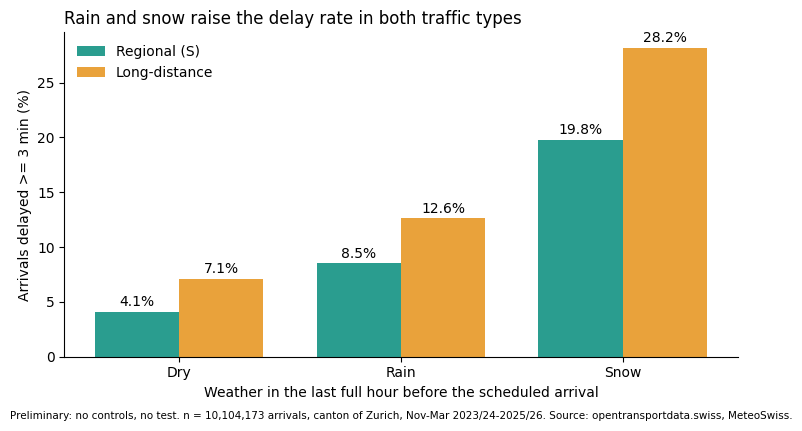

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
width = 0.38
x = range(len(order))
for i, t in enumerate(["regional", "long_distance"]):
    bars = ax.bar([p + (i - 0.5) * width for p in x], wide[t], width, color=COLORS[t], label=LABELS[t])
    ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=10)
ax.set_xticks(list(x)); ax.set_xticklabels(["Dry", "Rain", "Snow"])
ax.set_ylabel("Arrivals delayed >= 3 min (%)")
ax.set_xlabel("Weather in the last full hour before the scheduled arrival")
ax.set_title("Rain and snow raise the delay rate in both traffic types", loc="left", fontsize=12)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.01, f"Preliminary: no controls, no test. n = {n_total:,} arrivals, canton of Zurich, Nov-Mar 2023/24-2025/26. "
         "Source: opentransportdata.swiss, MeteoSwiss.", fontsize=7.5)
plt.tight_layout()
fig.savefig(OUT / "slide10_delay_rates.png", dpi=200, bbox_inches="tight")
plt.show()

## Findings
Run of 2026-11-10 on release `data-v1` (descriptive, no controls, no tests):

- The delay rate rises from dry to rain to snow in both traffic types (regional 4.1 % -> 8.5 % -> 19.8 %, long-distance 7.1 % -> 12.6 % -> 28.2 %).
- The pooled effect (rain + snow vs. dry) is +5.1 pp regional and +6.3 pp long-distance; this notebook does not decide which is "stronger" (hypothesis H2, test in #20).
- Snow rests on few arrivals (79,835 regional, 4,729 long-distance).

## Open questions
- The slide shows rain and snow separately, the primary effect uses rain + snow pooled (`precip_any`): say this on the slide.

### Jupyter notebook --footer info--

In [6]:
import os, platform
from platform import python_version
from datetime import datetime
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')